# Customer Churn Prediction and Retention Analysis

Customer churn refers to the situation where customers stop using a company's products or services. Predicting customer churn is important for businesses because retaining existing customers is often more cost-effective than acquiring new ones.

This project uses machine learning techniques to predict customers who are likely to leave a telecom service provider. It explores customer demographics, service subscriptions, contract details, billing information, and usage patterns to identify factors associated with churn.

Multiple classification algorithms, including Logistic Regression, Random Forest, and HistGradientBoosting, are trained and evaluated to identify the most suitable model. The project also analyzes churn patterns across different customer segments to generate insights that can help businesses understand customer behavior and develop better retention strategies.



## 1. Imports and configuration

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score, accuracy_score
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

DATA_PATH = Path("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
REPORTS_DIR, MODELS_DIR = Path("../reports"), Path("../models")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
print("Setup complete")

Setup complete


## 2. Load and inspect the data

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}. Download it from the Kaggle link above."
    )
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("Data type"))

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,Data type
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


## 3. Data cleaning

In [3]:
print("Missing values before cleaning:")
display(df.isna().sum().sort_values(ascending=False).head(10))

# customerID identifies a record; it is not a predictive feature.
if "customerID" in df.columns:
    print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

# Blank TotalCharges values are converted to NaN. These rows have tenure 0 (no bill yet),
# so TotalCharges is 0; any other missing value is imputed inside the pipeline.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
df.loc[df["TotalCharges"].isna() & df["tenure"].eq(0), "TotalCharges"] = 0.0
print("Missing TotalCharges after tenure-0 fix:", df["TotalCharges"].isna().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Cleaned shape:", df.shape)

Missing values before cleaning:


customerID         0
gender             0
SeniorCitizen      0
Partner            0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
OnlineSecurity     0
dtype: int64

Duplicate customer IDs: 0
Missing TotalCharges: 11
Missing TotalCharges after tenure-0 fix: 0
Cleaned shape: (7043, 21)


## 4. Exploratory data analysis

Overall churn rate: 26.54%


,Customers
Churn,
No,5174
Yes,1869


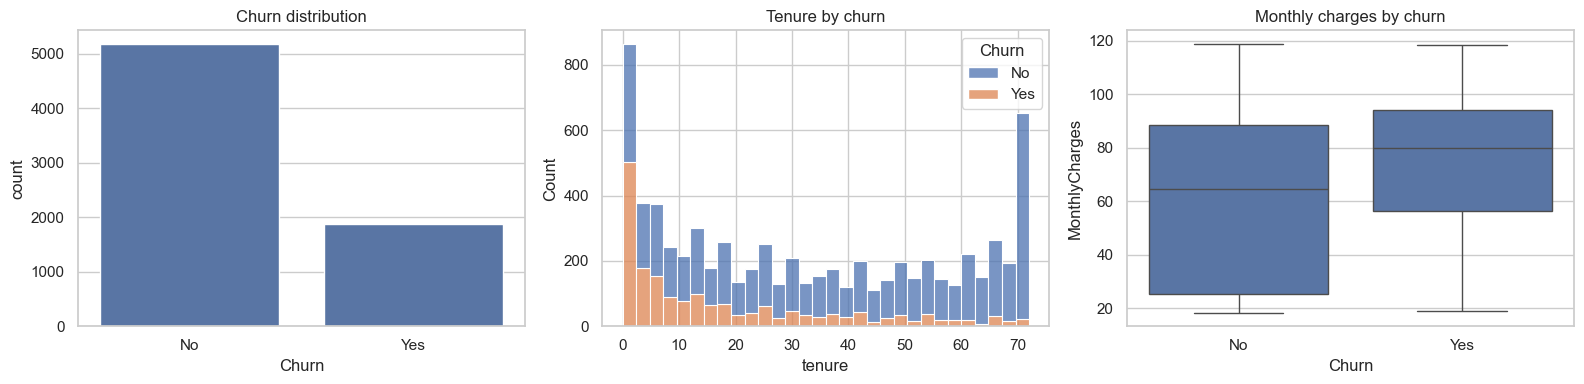

In [4]:
churn_rate = df["Churn"].eq("Yes").mean()
print(f"Overall churn rate: {churn_rate:.2%}")
display(df["Churn"].value_counts().rename("Customers").to_frame())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x="Churn", order=["No", "Yes"], ax=axes[0])
axes[0].set_title("Churn distribution")
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack", ax=axes[1])
axes[1].set_title("Tenure by churn")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", order=["No", "Yes"], ax=axes[2])
axes[2].set_title("Monthly charges by churn")
plt.tight_layout()
plt.show()

## 5. Churn across customer segments

Churn rate by Contract


,Churn rate (%)
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


Churn rate by PaymentMethod


,Churn rate (%)
PaymentMethod,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24


Churn rate by InternetService


,Churn rate (%)
InternetService,
Fiber optic,41.89
DSL,18.96
No,7.40


... (2 outputs left out)

Churn rate by OnlineSecurity


,Churn rate (%)
OnlineSecurity,
No,41.77
Yes,14.61
No internet service,7.40


Churn rate by PaperlessBilling


,Churn rate (%)
PaperlessBilling,
Yes,33.57
No,16.33


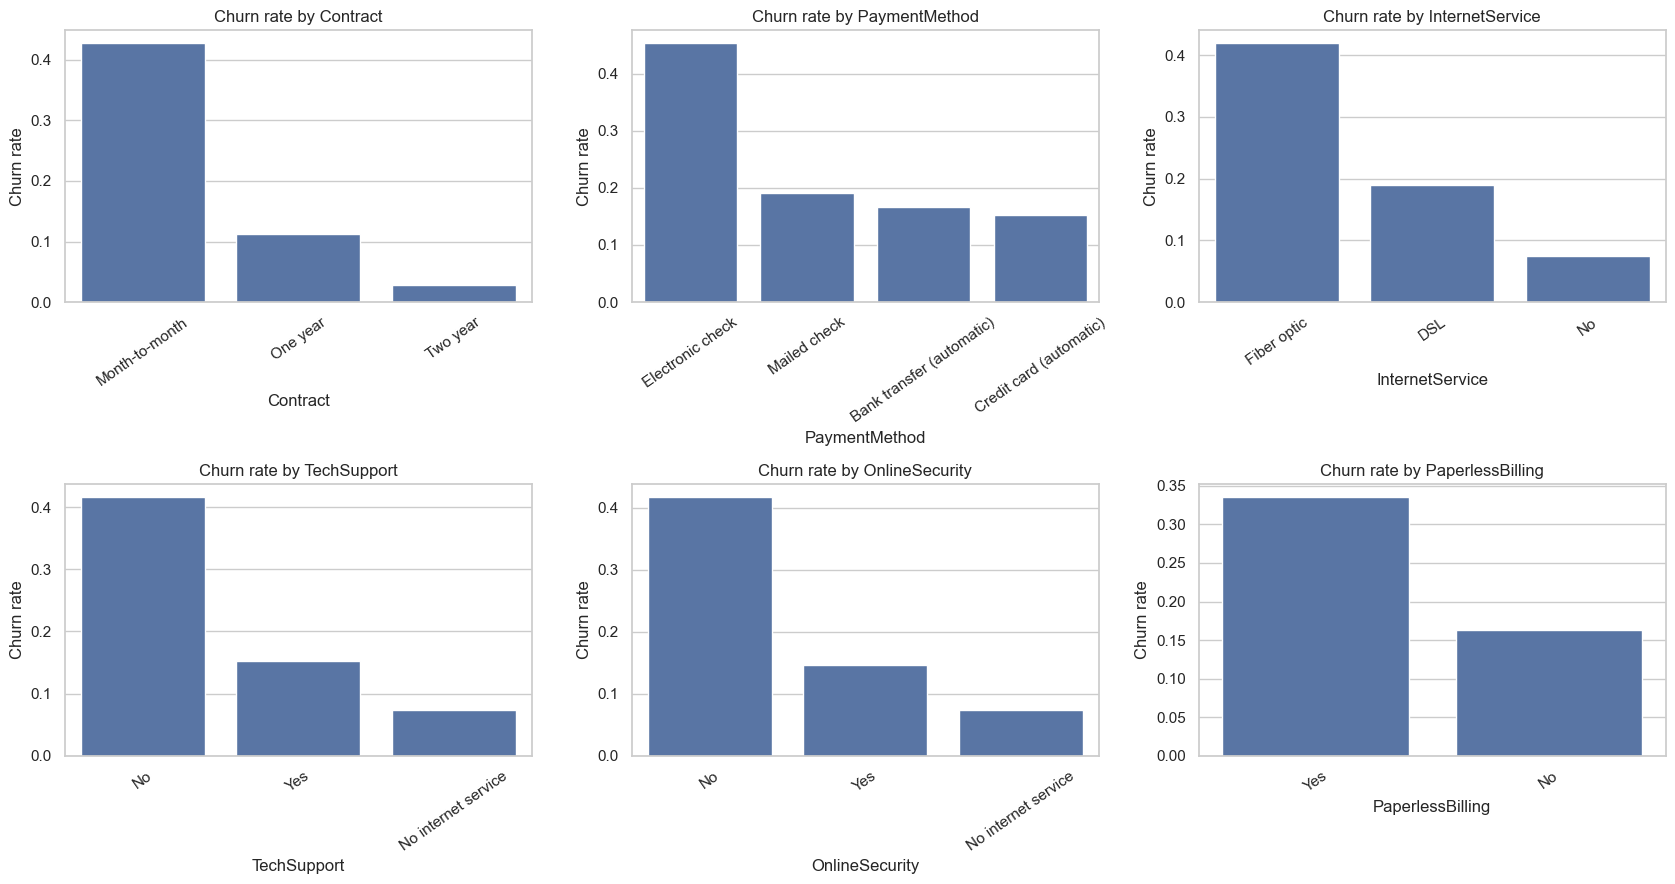

In [5]:
segment_columns = ["Contract", "PaymentMethod", "InternetService",
                   "TechSupport", "OnlineSecurity", "PaperlessBilling"]
segment_results = []
for col in segment_columns:
    rates = (df.groupby(col)["Churn"]
               .apply(lambda s: s.eq("Yes").mean())
               .sort_values(ascending=False))
    table = (rates * 100).rename("Churn rate (%)").to_frame()
    print(f"Churn rate by {col}")
    display(table.round(2))
    for segment, rate in rates.items():
        segment_results.append({"Feature": col, "Segment": segment, "Churn rate": rate})

segment_df = pd.DataFrame(segment_results)
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.flat, segment_columns):
    order = df.groupby(col)["Churn"].apply(lambda s: s.eq("Yes").mean()).sort_values(ascending=False).index
    sns.barplot(data=df, x=col, y=df["Churn"].eq("Yes").astype(int),
                order=order, estimator=np.mean, errorbar=None, ax=ax)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

## 6. Prepare features and split the data

In [6]:
TARGET = "Churn"
drop_cols = [TARGET] + (["customerID"] if "customerID" in df.columns else [])
X = df.drop(columns=drop_cols).copy()
y = df[TARGET].map({"No": 0, "Yes": 1}).astype(int)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, test_size=0.25,
    random_state=RANDOM_STATE, stratify=y_train_full
)
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)
print("Train / validation / test:", X_train.shape, X_valid.shape, X_test.shape)

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Train / validation / test: (4225, 19) (1409, 19) (1409, 19)


## 7. Preprocessing

In [7]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

## 8. Train and compare models

In [8]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced",
                                     random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=3,
            class_weight="balanced_subsample", n_jobs=-1,
            random_state=RANDOM_STATE))
    ]),
    "HistGradientBoosting": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", HistGradientBoostingClassifier(
            max_iter=150, learning_rate=0.08, max_leaf_nodes=15,
            l2_regularization=1.0, class_weight="balanced",
            random_state=RANDOM_STATE))
    ])
}
fitted_models, rows = {}, []
for name, pipe in models.items():
    print("Training:", name)
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    scores = pipe.predict_proba(X_valid)[:, 1]
    pred = (scores >= 0.5).astype(int)
    rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_valid, scores),
        "PR-AUC (Average Precision)": average_precision_score(y_valid, scores),
        "Precision @ 0.5": precision_score(y_valid, pred, zero_division=0),
        "Recall @ 0.5": recall_score(y_valid, pred, zero_division=0),
        "F1 @ 0.5": f1_score(y_valid, pred, zero_division=0)
    })
validation_results = pd.DataFrame(rows).sort_values("PR-AUC (Average Precision)", ascending=False)
display(validation_results)
validation_results.to_csv(REPORTS_DIR / "validation_model_comparison.csv", index=False)

Training: Logistic Regression
Training: Random Forest


Training: HistGradientBoosting


,Model,ROC-AUC,PR-AUC (Average Precision),Precision @ 0.5,Recall @ 0.5,F1 @ 0.5
0,Logistic Regression,0.836370,0.642583,0.515734,0.788770,0.623679
2,HistGradientBoosting,0.833085,0.639970,0.520947,0.764706,0.619718
1,Random Forest,0.831854,0.622561,0.559471,0.679144,0.613527


## 9. Precision-recall curves

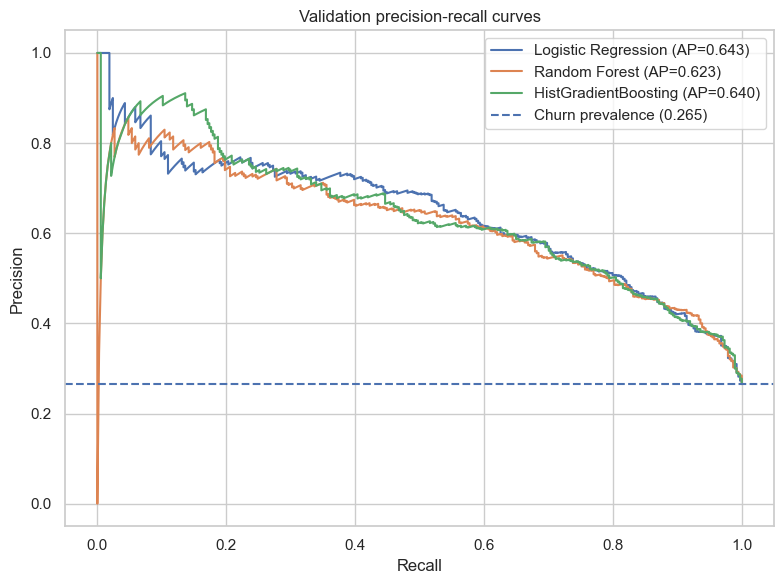

In [9]:
plt.figure(figsize=(8, 6))
for name, pipe in fitted_models.items():
    scores = pipe.predict_proba(X_valid)[:, 1]
    precision, recall, _ = precision_recall_curve(y_valid, scores)
    ap = average_precision_score(y_valid, scores)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")
plt.axhline(y_valid.mean(), linestyle="--", label=f"Churn prevalence ({y_valid.mean():.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation precision-recall curves")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Select a decision threshold

Selected model: Logistic Regression
Threshold: 0.6104
Validation precision / recall / F1: 0.5787 0.6979 0.6327


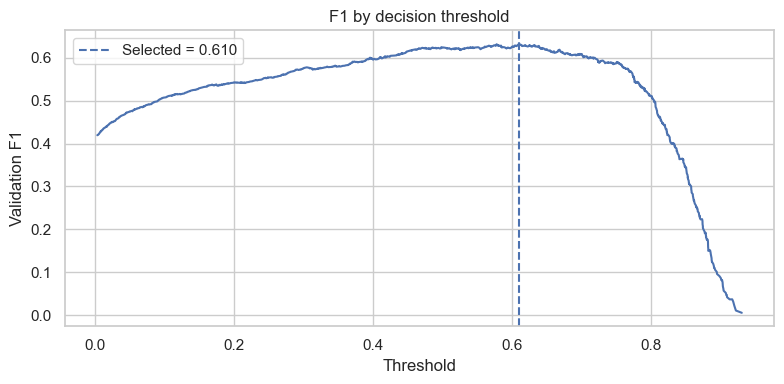

In [10]:
best_name = validation_results.iloc[0]["Model"]
best_model = fitted_models[best_name]
valid_scores = best_model.predict_proba(X_valid)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_valid, valid_scores)
f1_values = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-12)
best_idx = int(np.nanargmax(f1_values))
best_threshold = float(thresholds[best_idx])

print("Selected model:", best_name)
print("Threshold:", round(best_threshold, 4))
print("Validation precision / recall / F1:",
      round(float(precisions[best_idx]), 4),
      round(float(recalls[best_idx]), 4),
      round(float(f1_values[best_idx]), 4))

plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_values)
plt.axvline(best_threshold, linestyle="--", label=f"Selected = {best_threshold:.3f}")
plt.xlabel("Threshold")
plt.ylabel("Validation F1")
plt.title("F1 by decision threshold")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Final test evaluation

,Test result
Selected model,Logistic Regression
Threshold,0.610439
Accuracy,0.767211
Precision,0.547917
Recall,0.703209
F1-score,0.615925
ROC-AUC,0.842801
PR-AUC (Average Precision),0.633133


              precision    recall  f1-score   support

      Stayed       0.88      0.79      0.83      1035
     Churned       0.55      0.70      0.62       374

    accuracy                           0.77      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.77      0.78      1409



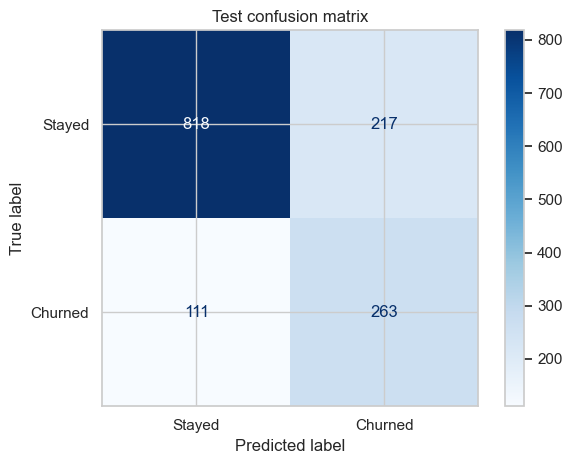

In [11]:
test_scores = best_model.predict_proba(X_test)[:, 1]
test_predictions = (test_scores >= best_threshold).astype(int)
test_metrics = {
    "Selected model": best_name,
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1-score": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_scores),
    "PR-AUC (Average Precision)": average_precision_score(y_test, test_scores)
}
display(pd.DataFrame([test_metrics]).T.rename(columns={0: "Test result"}))
print(classification_report(y_test, test_predictions,
                            target_names=["Stayed", "Churned"], zero_division=0))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, test_predictions),
    display_labels=["Stayed", "Churned"]
).plot(values_format="d", cmap="Blues")
plt.title("Test confusion matrix")
plt.tight_layout()
plt.show()
pd.DataFrame([test_metrics]).to_csv(REPORTS_DIR / "final_test_metrics.csv", index=False)

## 12. Model interpretation

,Feature,Importance
1,num__tenure,0.124157
36,cat__Contract_Month-to-month,0.114831
3,num__TotalCharges,0.111678
2,num__MonthlyCharges,0.085295
38,cat__Contract_Two year,0.059020
18,cat__OnlineSecurity_No,0.053572
27,cat__TechSupport_No,0.041801
16,cat__InternetService_Fiber optic,0.041726
43,cat__PaymentMethod_Electronic check,0.032665
21,cat__OnlineBackup_No,0.018194


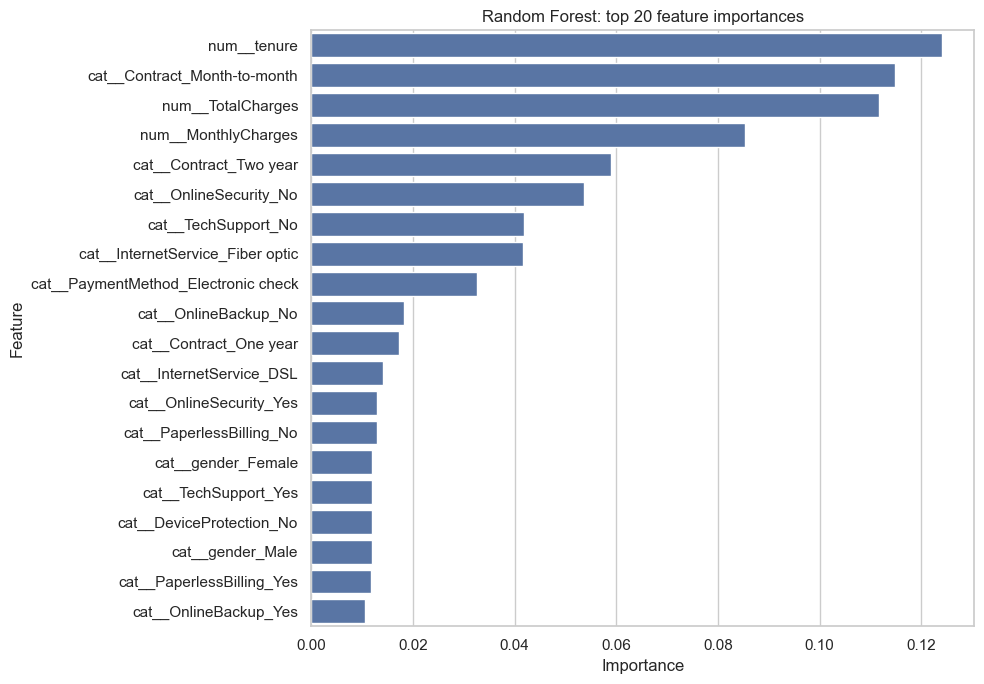

In [12]:
rf_pipe = fitted_models["Random Forest"]
feature_names = rf_pipe.named_steps["preprocess"].get_feature_names_out()
importances = rf_pipe.named_steps["model"].feature_importances_
importance_df = pd.DataFrame({
    "Feature": feature_names, "Importance": importances
}).sort_values("Importance", ascending=False).head(20)
display(importance_df)
plt.figure(figsize=(10, 7))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Random Forest: top 20 feature importances")
plt.tight_layout()
plt.show()
importance_df.to_csv(REPORTS_DIR / "feature_importance.csv", index=False)

## 13. Customer retention analysis

In [13]:
risk_analysis = X_test.copy()
risk_analysis["ActualChurn"] = y_test
risk_analysis["PredictedChurnProbability"] = test_scores
risk_analysis["PredictedHighRisk"] = test_predictions
risk_analysis["RiskBand"] = pd.cut(
    test_scores, bins=[-0.001, 0.30, 0.60, 1.001],
    labels=["Low", "Medium", "High"]
)

risk_summary = risk_analysis.groupby("RiskBand", observed=False).agg(
    Customers=("ActualChurn", "size"),
    AveragePredictedRisk=("PredictedChurnProbability", "mean"),
    ActualChurnRate=("ActualChurn", "mean")
)
risk_summary[["AveragePredictedRisk", "ActualChurnRate"]] *= 100
display(risk_summary.round(2))

if "Contract" in risk_analysis.columns:
    contract_summary = risk_analysis.groupby("Contract").agg(
        Customers=("ActualChurn", "size"),
        ActualChurnRate=("ActualChurn", "mean"),
        AveragePredictedRisk=("PredictedChurnProbability", "mean")
    )
    contract_summary[["ActualChurnRate", "AveragePredictedRisk"]] *= 100
    display(contract_summary.sort_values("AveragePredictedRisk", ascending=False).round(2))
    contract_summary.to_csv(REPORTS_DIR / "retention_segment_analysis.csv")

,Customers,AveragePredictedRisk,ActualChurnRate
RiskBand,,,
Low,604,10.40,4.14
Medium,315,44.41,26.03
High,490,77.18,54.49


,Customers,ActualChurnRate,AveragePredictedRisk
Contract,,,
Month-to-month,773,42.56,63.15
One year,300,12.00,23.31
Two year,336,2.68,6.79


In [14]:
high_risk_customers = risk_analysis.loc[
    risk_analysis["PredictedHighRisk"] == 1
].sort_values("PredictedChurnProbability", ascending=False)
display(high_risk_customers.head(10))
high_risk_customers.to_csv(REPORTS_DIR / "high_risk_test_customers.csv", index=False)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,ActualChurn,PredictedChurnProbability,PredictedHighRisk,RiskBand
3380,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.10,95.10,1,0.933528,1,High
6866,Male,0,No,No,1,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.45,95.45,1,0.923916,1,High
3727,Female,0,No,No,3,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,96.60,291.90,1,0.922731,1,High
4585,Female,1,No,No,1,Yes,Yes,Fiber optic,No,No,No,No,No,Yes,Month-to-month,Yes,Electronic check,85.05,85.05,1,0.921219,1,High
3346,Female,1,No,No,2,Yes,Yes,Fiber optic,No,No,No,No,No,Yes,Month-to-month,Yes,Electronic check,84.05,186.05,0,0.920398,1,High
2631,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.25,665.45,1,0.920074,1,High
935,Female,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,Yes,No,Month-to-month,Yes,Electronic check,83.25,308.05,0,0.918145,1,High
6365,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,101.95,700.85,1,0.918021,1,High
2797,Male,0,No,No,3,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.95,329.95,1,0.916499,1,High
582,Female,1,No,No,4,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,No,Month-to-month,Yes,Electronic check,89.20,346.20,1,0.916009,1,High


## 14. Save the trained model

In [15]:
model_path = MODELS_DIR / "customer_churn_model.joblib"
joblib.dump({
    "model": best_model,
    "threshold": best_threshold,
    "model_name": best_name,
    "feature_columns": list(X.columns)
}, model_path)
print("Saved:", model_path.resolve())
print("Reports:", REPORTS_DIR.resolve())

Saved: C:\Users\shaya\customer_churn_prediction\models\customer_churn_model.joblib
Reports: C:\Users\shaya\customer_churn_prediction\reports
